In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings("ignore")

# Load the existing Superstore dataset
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [2]:
# Select numerical columns
numerical_columns = ["Sales", "Quantity", "Discount", "Profit"]

# Calculate descriptive statistics
print("DESCRIPTIVE STATISTICS")
display(df[numerical_columns].describe().T)

# Additional statistical measures
additional_stats = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": df[numerical_columns].mode().iloc[0],
    "Variance": df[numerical_columns].var(),
    "Standard Deviation": df[numerical_columns].std(),
    "Skewness": df[numerical_columns].skew(),
    "Kurtosis": df[numerical_columns].kurt()
})

display(additional_stats.round(3))

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Sales,10194.0,228.225854,619.906839,0.444,17.2200,53.91,209.500000,22638.480
Quantity,10194.0,3.791838,2.228317,1.000,2.0000,3.00,5.000000,14.000
Discount,10194.0,0.155385,0.206249,0.000,0.0000,0.20,0.200000,0.800
Profit,10194.0,28.673417,232.465115,-6599.978,1.7608,8.69,29.297925,8399.976


,Mean,Median,Mode,Variance,Standard Deviation,Skewness,Kurtosis
Sales,228.226,53.91,12.96,384284.489,619.907,12.984,306.366
Quantity,3.792,3.00,2.00,4.965,2.228,1.269,1.962
Discount,0.155,0.20,0.00,0.043,0.206,1.687,2.416
Profit,28.673,8.69,0.00,54040.030,232.465,7.605,401.693


In [3]:
# Separate profit values by discount status
no_discount = df.loc[df["Discount"] == 0, "Profit"].dropna()
with_discount = df.loc[df["Discount"] > 0, "Profit"].dropna()

# Welch's independent-samples t-test
t_stat, p_value = stats.ttest_ind(
    no_discount,
    with_discount,
    equal_var=False
)

print("HYPOTHESIS TEST: DISCOUNT AND PROFIT")
print("No-discount transactions:", len(no_discount))
print("Discounted transactions:", len(with_discount))
print("Mean profit without discount:", round(no_discount.mean(), 2))
print("Mean profit with discount:", round(with_discount.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Conclusion: Reject the null hypothesis.")
    print("The mean profits differ significantly between the two groups.")
else:
    print("Conclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean profits.")

HYPOTHESIS TEST: DISCOUNT AND PROFIT
No-discount transactions: 4925
Discounted transactions: 5269
Mean profit without discount: 66.34
Mean profit with discount: -6.53
T-statistic: 15.8941
P-value: 3.7270202073140507e-56
Conclusion: Reject the null hypothesis.
The mean profits differ significantly between the two groups.


MONTHLY SALES TIME SERIES
Number of months: 48


Order Date
2023-01-01    14518.055
2023-02-01     4519.892
2023-03-01    56933.909
2023-04-01    28295.345
2023-05-01    26319.767
Freq: MS, Name: Sales, dtype: float64

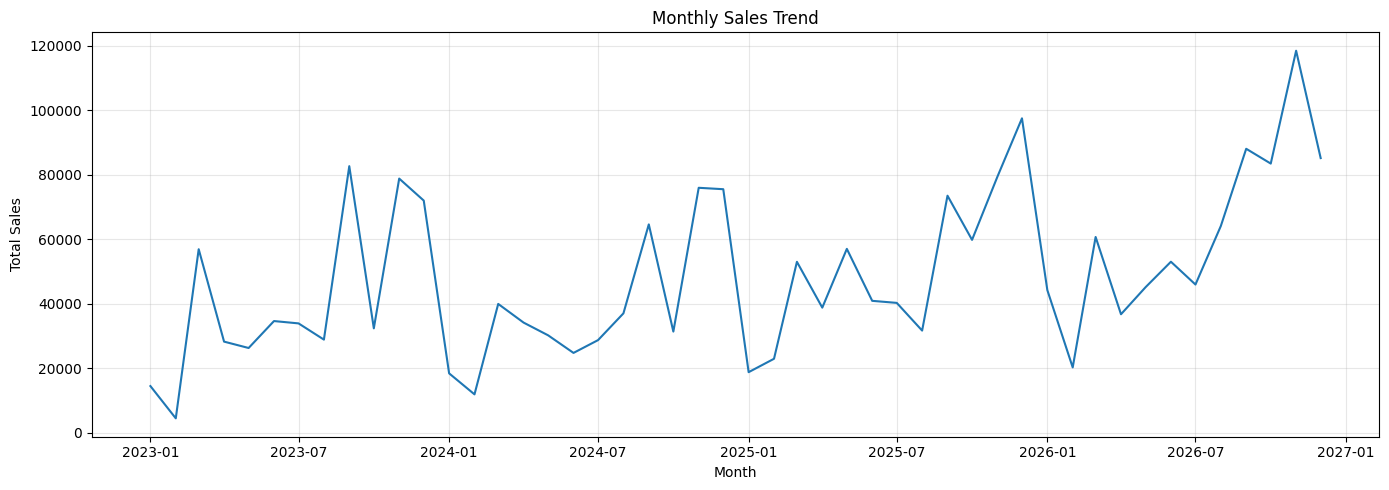

In [4]:
# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Create monthly sales time series
monthly_sales = (
    df.set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
)

print("MONTHLY SALES TIME SERIES")
print("Number of months:", len(monthly_sales))
display(monthly_sales.head())

# Plot monthly sales
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

TIME-SERIES SUMMARY
Number of months: 48
Start date: 2023-01-01
End date: 2026-12-01
Total sales: 2326534.35

First 5 months:


Order Date
2023-01-01    14518.055
2023-02-01     4519.892
2023-03-01    56933.909
2023-04-01    28295.345
2023-05-01    26319.767
Freq: MS, Name: Sales, dtype: float64

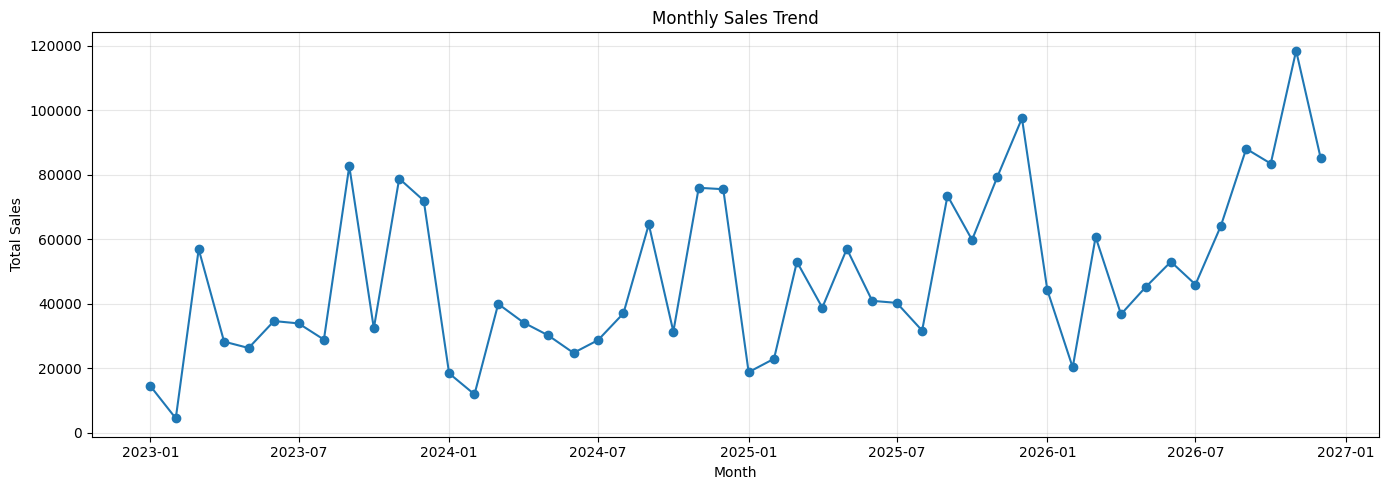

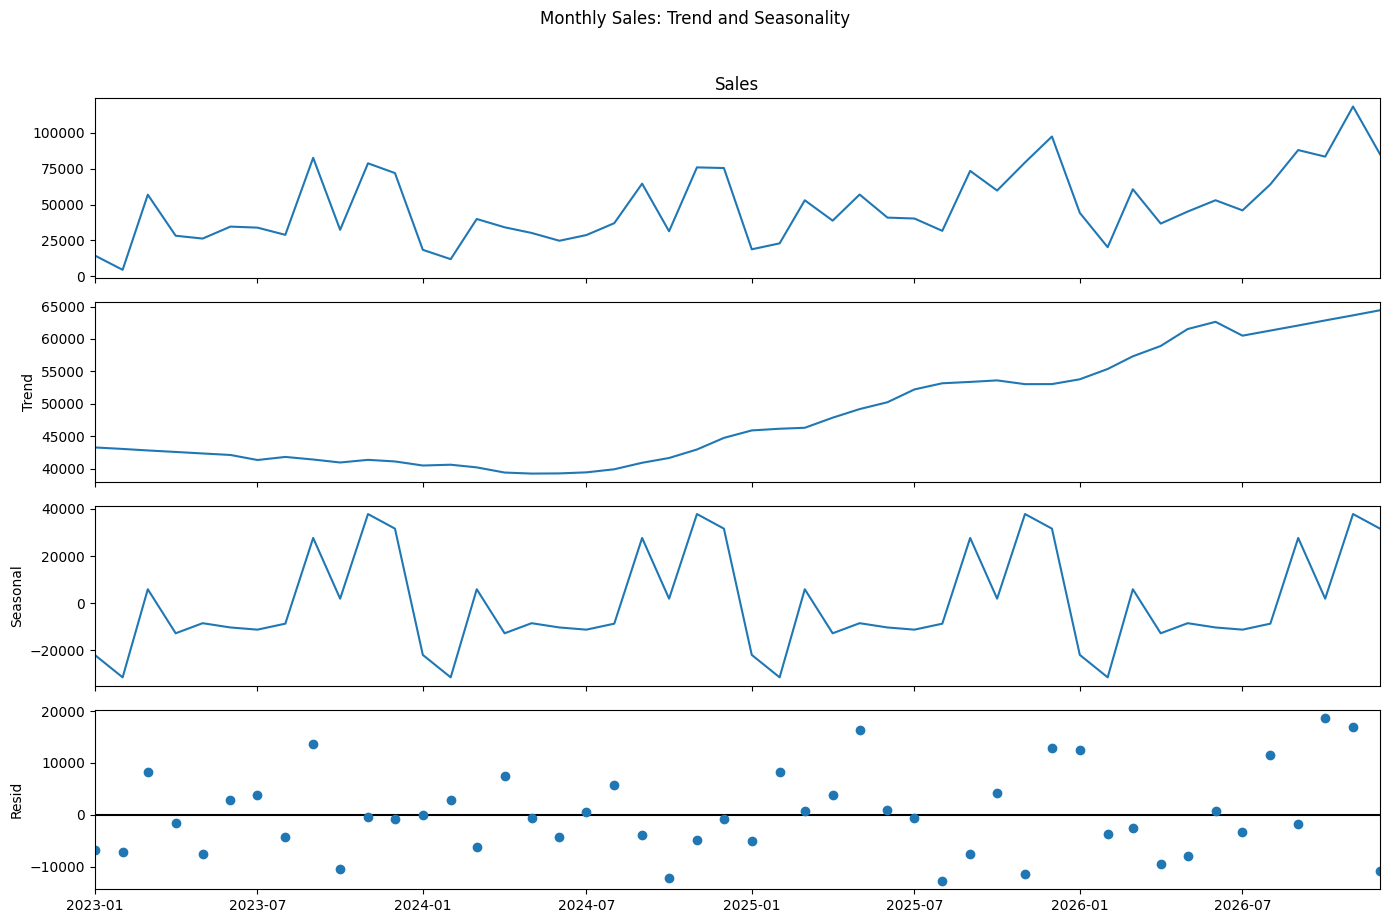


ADF STATIONARITY TEST
ADF statistic: -4.4375
P-value: 0.000255
Critical value (5%): -2.9253
Conclusion: Reject the null hypothesis of a unit root.
The series appears stationary according to the ADF test.

Business interpretation:
The monthly chart shows how sales change over time.
The decomposition separates the estimated trend, seasonal pattern,
and unexplained residual variation.
The ADF result helps determine whether differencing may be needed
before fitting certain forecasting models.


In [3]:
# TASK 4: TIME-SERIES ANALYSIS
# Trend, seasonality, residuals, and stationarity testing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")

# 1. Prepare the date column
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# 2. Calculate monthly sales
monthly_sales = (
    df.dropna(subset=["Order Date", "Sales"])
      .set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
      .asfreq("MS")
)

# Fill any missing months, if present
monthly_sales = monthly_sales.fillna(0)

print("TIME-SERIES SUMMARY")
print("Number of months:", len(monthly_sales))
print("Start date:", monthly_sales.index.min().date())
print("End date:", monthly_sales.index.max().date())
print("Total sales:", round(monthly_sales.sum(), 2))
print("\nFirst 5 months:")
display(monthly_sales.head())

# 3. Plot monthly sales
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Decompose sales into trend, seasonality, and residuals
if len(monthly_sales) >= 24:
    decomposition = seasonal_decompose(
        monthly_sales,
        model="additive",
        period=12,
        extrapolate_trend="freq"
    )

    decomposition.plot()
    plt.gcf().set_size_inches(14, 9)
    plt.suptitle("Monthly Sales: Trend and Seasonality", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("At least 24 months are recommended for yearly seasonal decomposition.")

# 5. Augmented Dickey-Fuller (ADF) stationarity test
adf_result = adfuller(monthly_sales.dropna(), autolag="AIC")

adf_statistic = adf_result[0]
p_value = adf_result[1]
critical_value_5 = adf_result[4]["5%"]

print("\nADF STATIONARITY TEST")
print("ADF statistic:", round(adf_statistic, 4))
print("P-value:", round(p_value, 6))
print("Critical value (5%):", round(critical_value_5, 4))

if p_value < 0.05:
    print("Conclusion: Reject the null hypothesis of a unit root.")
    print("The series appears stationary according to the ADF test.")
else:
    print("Conclusion: Fail to reject the null hypothesis of a unit root.")
    print("The series may be non-stationary.")

print("\nBusiness interpretation:")
print("The monthly chart shows how sales change over time.")
print("The decomposition separates the estimated trend, seasonal pattern,")
print("and unexplained residual variation.")
print("The ADF result helps determine whether differencing may be needed")
print("before fitting certain forecasting models.")

In [7]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 10.3 MB/s  0:00:01eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Load the Superstore dataset again
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


FORECAST EVALUATION
MAE: 11752.42
RMSE: 13071.68
MAPE: 22.52 %


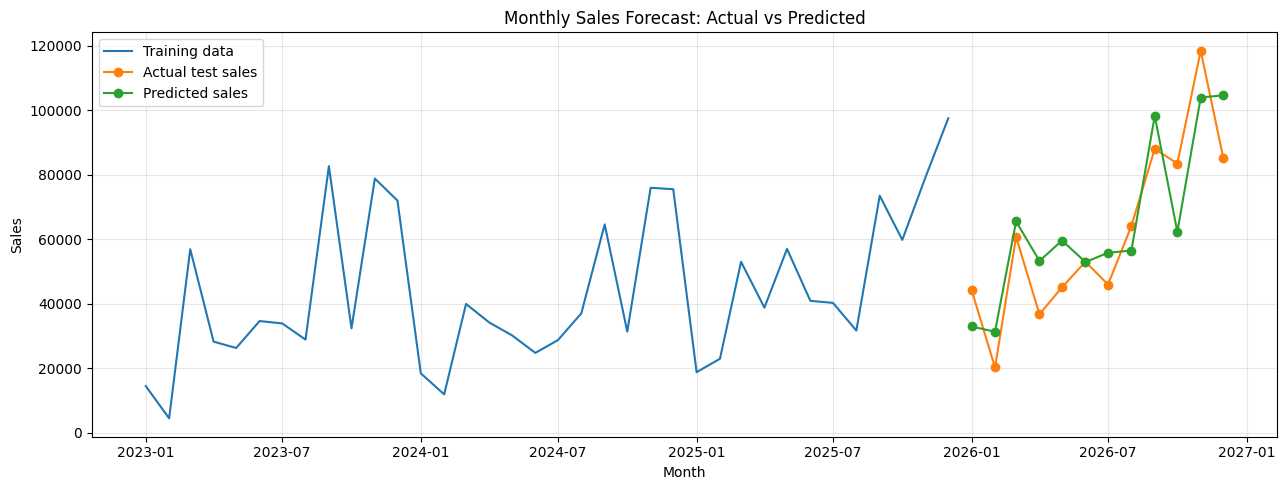

NEXT 6 MONTHS FORECAST


,Forecast Sales
2027-01-01,51138.83
2027-02-01,43083.85
2027-03-01,77514.46
2027-04-01,62984.26
2027-05-01,70407.56
2027-06-01,67041.04


In [4]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the last 12 months as test data
train = monthly_sales.iloc[:-12]
test = monthly_sales.iloc[-12:]

# Fit a trend and yearly seasonal pattern
model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

fitted_model = model.fit()
predictions = fitted_model.forecast(len(test))

# Evaluate forecast accuracy
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))

# Avoid division by zero when calculating MAPE
nonzero = test != 0
mape = (
    np.mean(np.abs((test[nonzero] - predictions[nonzero]) / test[nonzero]))
    * 100
)

print("FORECAST EVALUATION")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

# Plot actual vs predicted sales
plt.figure(figsize=(13, 5))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test sales", marker="o")
plt.plot(predictions.index, predictions, label="Predicted sales", marker="o")
plt.title("Monthly Sales Forecast: Actual vs Predicted")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Refit using all available data and forecast the next 6 months
final_model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

future_forecast = final_model.forecast(6)

print("NEXT 6 MONTHS FORECAST")
display(future_forecast.rename("Forecast Sales").to_frame().round(2))

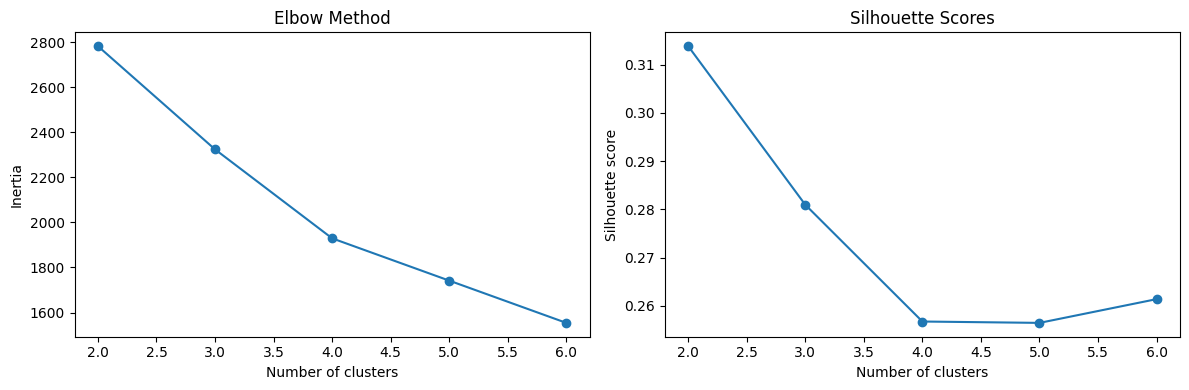

Silhouette scores:
k=2: 0.314
k=3: 0.281
k=4: 0.257
k=5: 0.256
k=6: 0.261


,Customer_Count,Average_Sales,Average_Profit,Average_Quantity,Average_Discount,Average_Orders
Cluster,,,,,,
0,202,1551.19,-96.28,32.09,0.26,4.69
1,264,3712.55,367.00,69.67,0.16,8.81
2,55,9717.80,2281.43,81.24,0.12,8.62
3,283,1761.84,315.83,32.89,0.09,4.84


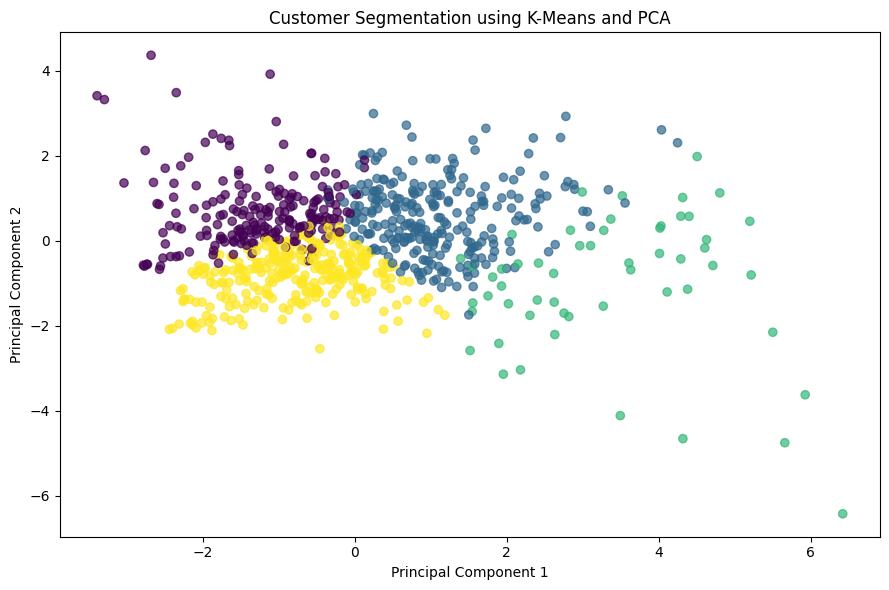

Variance explained by the two PCA components: 73.36 %


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Aggregate transactions into one row per customer
customer_data = df.groupby("Customer ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean"),
    Number_of_Orders=("Order ID", "nunique")
).reset_index()

features = [
    "Total_Sales",
    "Total_Profit",
    "Total_Quantity",
    "Average_Discount",
    "Number_of_Orders"
]

# Standardize features so larger scales do not dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_data[features])

# Compare cluster counts using inertia and silhouette score
inertias = []
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Scores")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.3f}")

# Use 4 clusters as an initial model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

# Summarize the customer groups
cluster_summary = customer_data.groupby("Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Average_Sales=("Total_Sales", "mean"),
    Average_Profit=("Total_Profit", "mean"),
    Average_Quantity=("Total_Quantity", "mean"),
    Average_Discount=("Average_Discount", "mean"),
    Average_Orders=("Number_of_Orders", "mean")
).round(2)

display(cluster_summary)

# Visualize clusters in two dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=customer_data["Cluster"],
    cmap="viridis",
    alpha=0.7
)
plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

,Model,MAE,RMSE,R2
0,Linear Regression,61.709,214.026,0.489
1,Decision Tree,28.787,120.929,0.837


Top 10 important features:


,Importance
Sales,0.604109
Discount,0.275223
Sub-Category_Supplies,0.034778
Region_East,0.027072
Region_South,0.013911
Sub-Category_Binders,0.009888
Segment_Corporate,0.009692
Sub-Category_Machines,0.007568
Quantity,0.006009
Sub-Category_Copiers,0.004532


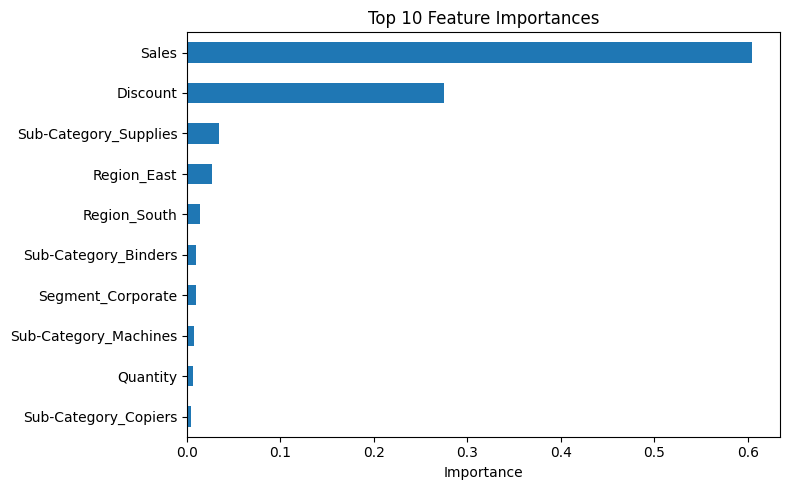

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare prediction dataset
model_df = df[
    ["Sales", "Quantity", "Discount", "Profit", "Ship Mode",
     "Segment", "Category", "Sub-Category", "Region"]
].dropna().copy()

# Convert categorical features into numeric columns
X = pd.get_dummies(
    model_df.drop(columns="Profit"),
    drop_first=True
)
y = model_df["Profit"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train two regression models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).round(3)
display(results_df)

# Feature importance from the Decision Tree
tree_model = models["Decision Tree"]
importance = pd.Series(
    tree_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 important features:")
display(importance.head(10).to_frame("Importance"))

importance.head(10).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Feature Importances"
)
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Task 4: Advanced Analytics and Statistical Modeling — Conclusion

## 1. Descriptive Statistics
Calculated mean, median, mode, variance, standard deviation, skewness, and kurtosis for Sales, Quantity, Discount, and Profit. Sales and Profit showed strong right-skewness, indicating the presence of unusually large transactions.

## 2. Hypothesis Testing
An independent-samples Welch's t-test compared profit on discounted and non-discounted transactions. The p-value was approximately 3.73 × 10⁻⁵⁶, indicating a statistically significant difference in mean profit. This association does not establish causation.

## 3. Time-Series Analysis and Forecasting
Analyzed 48 months of sales data and decomposed the series into trend, seasonality, and residual components. The Augmented Dickey-Fuller test returned a p-value of 0.000255. Exponential Smoothing produced a 12-month holdout MAPE of 22.52%, and a six-month sales forecast was generated for January–June 2027.

## 4. Customer Segmentation
Applied StandardScaler and K-Means to group 804 customers using sales, profit, quantity, discount, and order count. Four clusters were examined to develop customer-specific business recommendations. The best silhouette score among the tested values was 0.314 at k = 2, so the four-cluster solution should be treated as a more detailed exploratory segmentation rather than the best-separated solution.

## 5. Predictive Modeling
Compared Linear Regression and Decision Tree Regression for profit prediction.

- Linear Regression: MAE = 61.709, RMSE = 214.026, R² = 0.489.
- Decision Tree: MAE = 28.787, RMSE = 120.929, R² = 0.837.

The Decision Tree performed better on the held-out test set. Sales and Discount were its two most important features.

## 6. Limitations
- Results depend on the quality and characteristics of the available dataset.
- Statistical significance does not establish causation.
- Forecasts are estimates and may not reflect actual future sales.
- Customer clusters depend on the selected features and number of clusters.
- Predictive metrics come from one train/test split and may change with different data splits.
- Feature importance does not imply that a feature causes changes in profit.

## 7. Conclusion
This project applied descriptive and inferential statistics, time-series analysis, forecasting, customer segmentation, and regression modeling to the Sample Superstore dataset. The findings demonstrate how analytics can support sales planning, customer targeting, and profitability analysis.